## ETFs por país y región

Comparación de ETFs de renta variable internacional con **SPY** como referencia de EE.UU. Datos vía Yahoo Finance; las cifras citadas en texto corresponden a las salidas guardadas al ejecutar las celdas.



## Evolución normalizada (2016–2026)

Gráfico con precios de cierre, base 1.


C:\Users\nicon\AppData\Local\Temp\ipykernel_26656\21436881.py:17: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(etfs, start="2016-01-01", end="2026-01-01")["Close"]
[*********************100%***********************]  39 of 39 completed


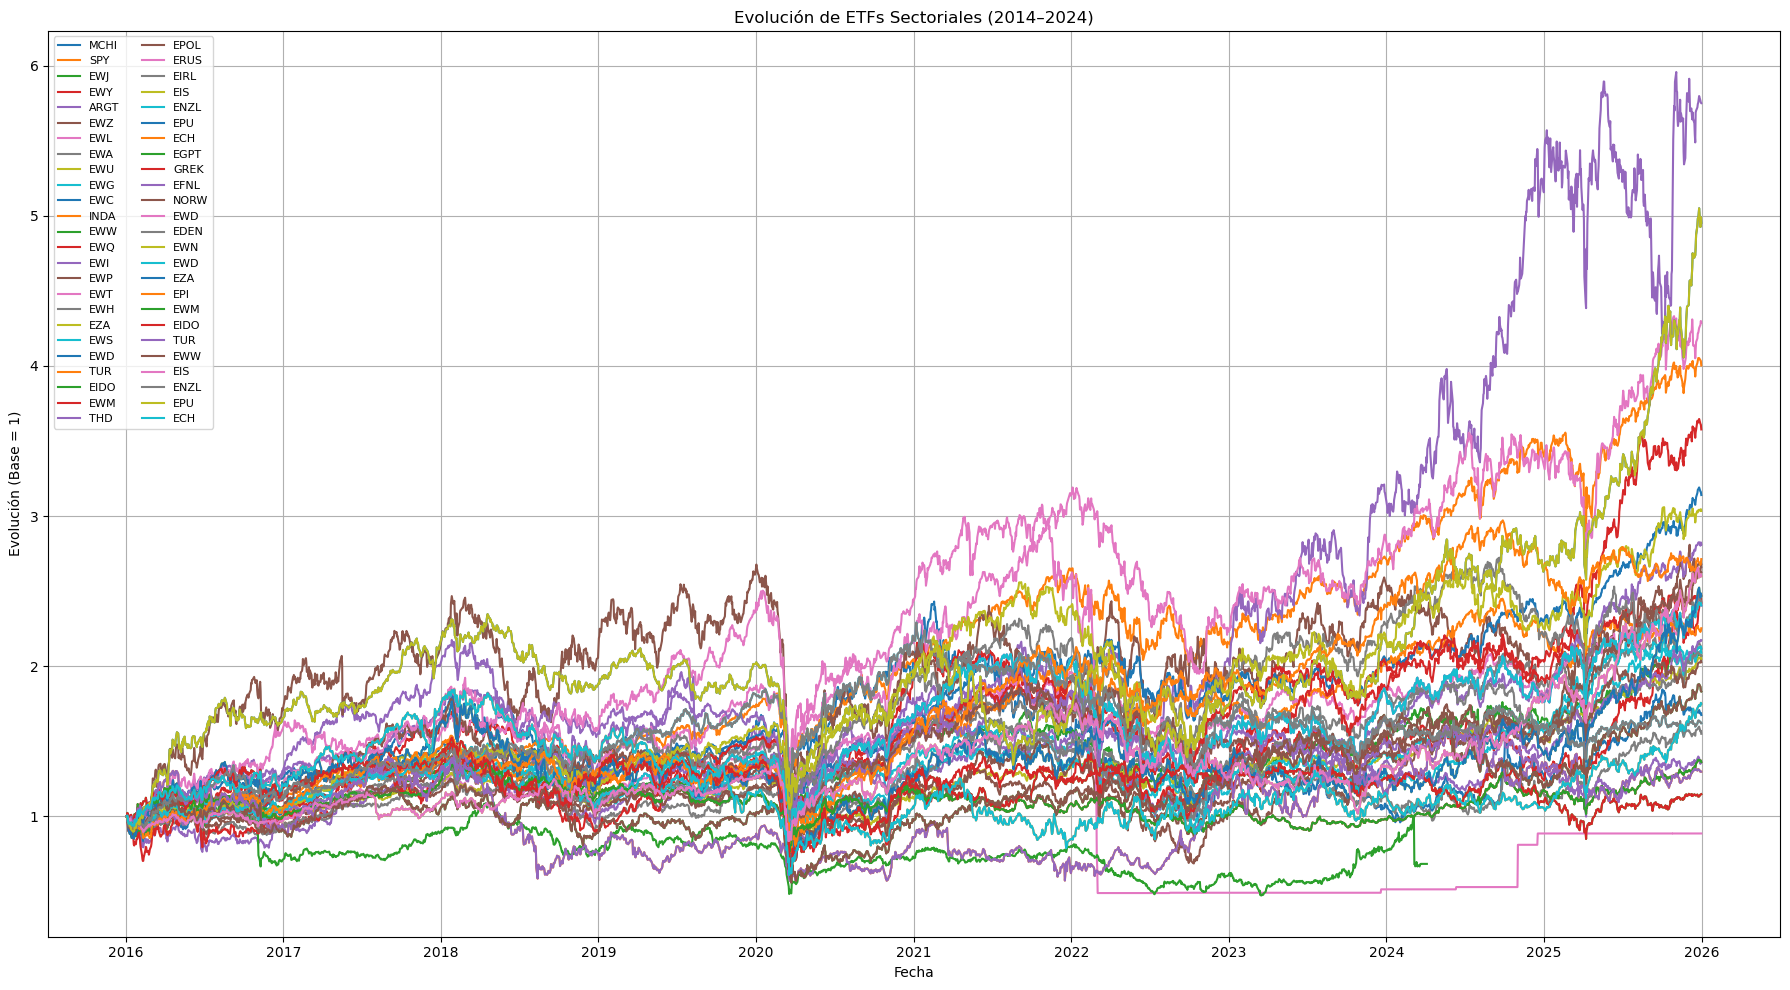

In [1]:
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

etfs = [
"MCHI", "SPY", "EWJ", "EWY", "ARGT", "EWZ", "EWL", "EWA", "EWU", "EWG", "EWC", "INDA",
"EWW", "EWQ", "EWI", "EWP", "EWT", "EWH", "EZA", "EWS", "EWD", "TUR", "EIDO", "EWM", "THD",
"EPOL", "ERUS", "EIRL", "EIS", "ENZL", "EPU", "ECH", "EGPT", "GREK", "EFNL", "NORW", "EWD",
"EDEN", "EWN", "EWD", "EZA", "EPI", "EWM", "EIDO", "TUR", "EWW", "EIS", "ENZL", "EPU", "ECH"
]

# Descargar precios ajustados desde 2014 (auto_adjust=True por defecto)
data = yf.download(etfs, start="2016-01-01", end="2026-01-01")["Close"]

# Normalizar (base 1)
data_normalizada = data / data.iloc[0]

# Graficar
plt.figure(figsize=(18, 10))
for etf in etfs:
    plt.plot(data_normalizada[etf], label=etf)

plt.title("Evolución de ETFs por país/región (2016–2026)")
plt.xlabel("Fecha")
plt.ylabel("Evolución (Base = 1)")
plt.legend(loc="upper left", fontsize=8, ncol=2)
plt.grid(True)
plt.tight_layout()
plt.show()


## Crecimiento total (2010–2025)

### Top 10


[*********************100%***********************]  39 of 39 completed
C:\Users\nicon\AppData\Local\Temp\ipykernel_26656\4257895747.py:32: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns = close_prices.pct_change().dropna()



Top 10 ETFs que más crecieron (2010-2025):

+----------+-------------------+
| Ticker   |   Crecimiento (%) |
|----------+-------------------|
| SPY      |            707.98 |
| EWT      |            363.91 |
| EWN      |            283.86 |
| EWL      |            271.93 |
| EWD      |            248.2  |
| EPU      |            242.61 |
| NORW     |            201.25 |
| EWC      |            182.67 |
| EWJ      |            171.74 |
| EWG      |            169.18 |
+----------+-------------------+


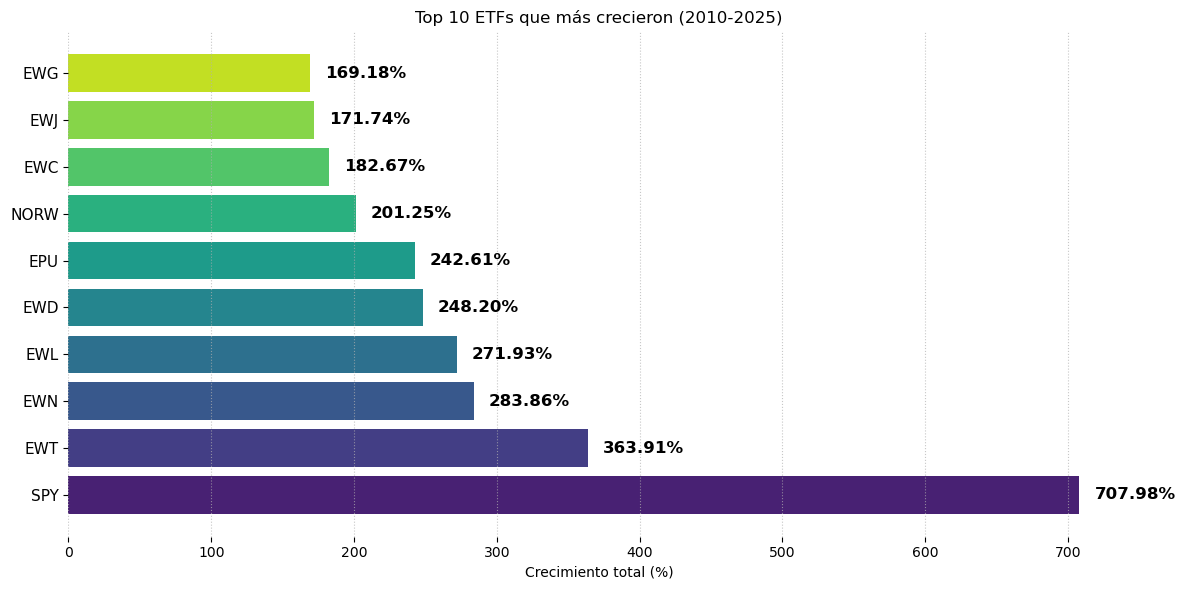

In [2]:
try:
    from tabulate import tabulate
except ImportError:
    tabulate = None

etfs = [
"MCHI", "SPY", "EWJ", "EWY", "ARGT", "EWZ", "EWL", "EWA", "EWU", "EWG", "EWC", "INDA",
"EWW", "EWQ", "EWI", "EWP", "EWT", "EWH", "EZA", "EWS", "EWD", "TUR", "EIDO", "EWM", "THD",
"EPOL", "ERUS", "EIRL", "EIS", "ENZL", "EPU", "ECH", "EGPT", "GREK", "EFNL", "NORW", "EWD",
"EDEN", "EWN", "EWD", "EZA", "EPI", "EWM", "EIDO", "TUR", "EWW", "EIS", "ENZL", "EPU", "ECH"
]

start_date = '2010-01-01'
end_date = '2025-12-31'

# Descargar datos de cierre ajustado
data = yf.download(etfs, start=start_date, end=end_date, group_by='ticker', auto_adjust=True)

# Extraer precios de cierre
if isinstance(data.columns, pd.MultiIndex):
    close_prices = data.xs('Close', axis=1, level=1)
else:
    close_prices = data[['Close']]

# Eliminar ETFs sin datos
close_prices = close_prices.dropna(axis=1, how='all')

# Calcular el retorno total de cada ETF en el periodo
growth = (close_prices.iloc[-1] / close_prices.iloc[0]) - 1

# Calcular desvío estándar de los retornos diarios
returns = close_prices.pct_change().dropna()
std_devs = returns.std()

# Crear un DataFrame con los resultados
result = pd.DataFrame({
    'Crecimiento (%)': growth * 100,
    'Desvío estándar': std_devs
})

# Ordenar por crecimiento descendente y mostrar top 10
top_10 = result.sort_values(by='Crecimiento (%)', ascending=False).head(10)
top_10 = top_10.round(2)

# --- Salida bonita en consola ---
print("\n" + "="*60)
print("Top 10 ETFs que más crecieron (2010-2025):\n")
if tabulate:
    print(tabulate(top_10[['Crecimiento (%)']], headers='keys', tablefmt='psql', showindex=True))
else:
    print(top_10[['Crecimiento (%)']])

# --- Visualización solo con variación ---
plt.figure(figsize=(12,6))
bars = plt.barh(top_10.index, top_10['Crecimiento (%)'], color=sns.color_palette("viridis", len(top_10)))

plt.gca().set_ylabel("")
plt.yticks(ticks=range(len(top_10.index)), labels=top_10.index, fontsize=11)
plt.xlabel('Crecimiento total (%)')
plt.title('Top 10 ETFs que más crecieron (2010-2025)')

# Quitar todos los bordes (spines)
for spine in plt.gca().spines.values():
    spine.set_visible(False)

# Solo la variación fuera de la barra, bien posicionada
for i, (etf, row) in enumerate(top_10.iterrows()):
    val = row['Crecimiento (%)']
    x_pos = val + max(top_10['Crecimiento (%)']) * 0.015
    plt.text(x_pos, i, f"{val:.2f}%", va='center', ha='left', fontsize=12, fontweight='bold')

plt.grid(axis='x', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

### Bottom 10 (2010–2026 en la celda de código)


[*********************100%***********************]  39 of 39 completed
C:\Users\nicon\AppData\Local\Temp\ipykernel_26656\916455007.py:32: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns = close_prices.pct_change().dropna()



Top 10 ETFs que MENOS crecieron (2010-2025):

+----------+-------------------+-------------------+
| Ticker   |   Crecimiento (%) |   Desvío estándar |
|----------+-------------------+-------------------|
| EWZ      |            -17.36 |              0.02 |
| TUR      |             -7.67 |              0.02 |
| ECH      |              7.29 |              0.02 |
| EWM      |             50.69 |              0.01 |
| EWW      |             93.03 |              0.01 |
| EWP      |            106.88 |              0.01 |
| THD      |            113.77 |              0.01 |
| EWA      |            122.23 |              0.01 |
| EWH      |            122.44 |              0.01 |
| EWI      |            123.19 |              0.02 |
+----------+-------------------+-------------------+


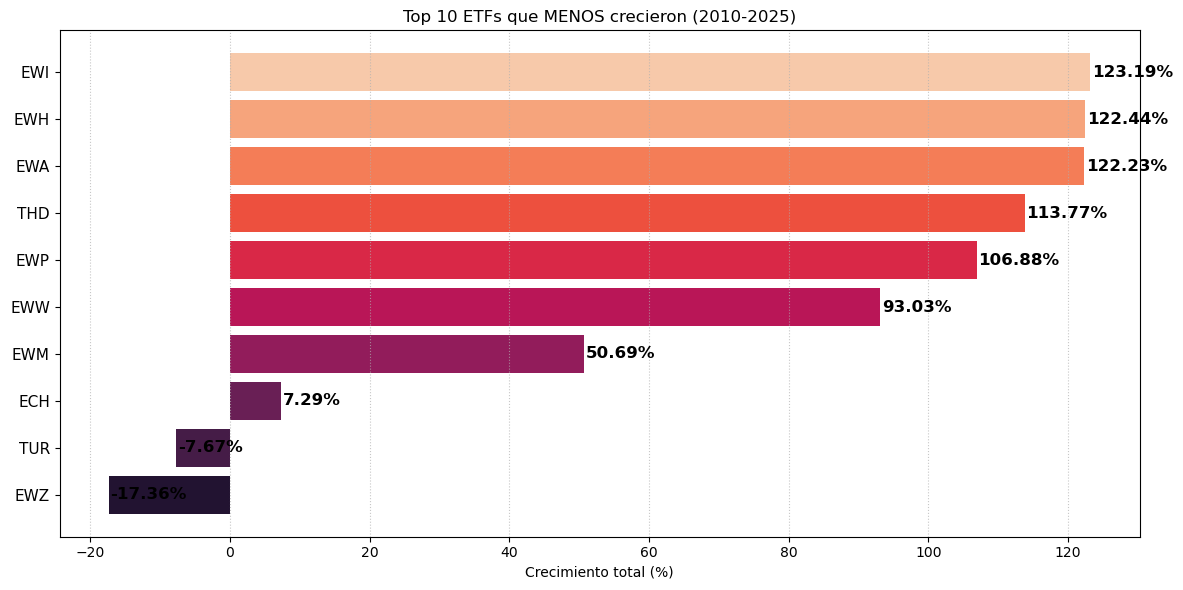

In [3]:
try:
    from tabulate import tabulate
except ImportError:
    tabulate = None

etfs = [
"MCHI", "SPY", "EWJ", "EWY", "ARGT", "EWZ", "EWL", "EWA", "EWU", "EWG", "EWC", "INDA",
"EWW", "EWQ", "EWI", "EWP", "EWT", "EWH", "EZA", "EWS", "EWD", "TUR", "EIDO", "EWM", "THD",
"EPOL", "ERUS", "EIRL", "EIS", "ENZL", "EPU", "ECH", "EGPT", "GREK", "EFNL", "NORW", "EWD",
"EDEN", "EWN", "EWD", "EZA", "EPI", "EWM", "EIDO", "TUR", "EWW", "EIS", "ENZL", "EPU", "ECH"
]

start_date = '2010-01-01'
end_date = '2026-01-01'

# Descargar datos de cierre ajustado
data = yf.download(etfs, start=start_date, end=end_date, group_by='ticker', auto_adjust=True)

# Extraer precios de cierre
if isinstance(data.columns, pd.MultiIndex):
    close_prices = data.xs('Close', axis=1, level=1)
else:
    close_prices = data[['Close']]

# Eliminar ETFs sin datos
close_prices = close_prices.dropna(axis=1, how='all')

# Calcular el retorno total de cada ETF en el periodo
growth = (close_prices.iloc[-1] / close_prices.iloc[0]) - 1

# Calcular desvío estándar de los retornos diarios
returns = close_prices.pct_change().dropna()
std_devs = returns.std()

# Crear un DataFrame con los resultados
result = pd.DataFrame({
    'Crecimiento (%)': growth * 100,
    'Desvío estándar': std_devs
})

# Ordenar por menor crecimiento y mostrar bottom 10
bottom_10 = result.sort_values(by='Crecimiento (%)', ascending=True).head(10)
bottom_10 = bottom_10.round(2)

# --- Salida bonita en consola ---
print("\n" + "="*60)
print("Top 10 ETFs que MENOS crecieron (2010-2025):\n")
if tabulate:
    print(tabulate(bottom_10, headers='keys', tablefmt='psql', showindex=True))
else:
    print(bottom_10)

# --- (Opcional) Visualización ---
plt.figure(figsize=(12,6))
bars = plt.barh(bottom_10.index, bottom_10['Crecimiento (%)'], color=sns.color_palette("rocket", len(bottom_10)))
plt.gca().set_ylabel("")
plt.yticks(ticks=range(len(bottom_10.index)), labels=bottom_10.index, fontsize=11)
plt.xlabel('Crecimiento total (%)')
plt.title('Top 10 ETFs que MENOS crecieron (2010-2025)')

for i, (etf, row) in enumerate(bottom_10.iterrows()):
    val = row['Crecimiento (%)']
    x_pos = val + max(1, abs(bottom_10['Crecimiento (%)'].min())) * 0.015
    plt.text(x_pos, i, f"{val:.2f}%", va='center', ha='left', fontsize=12, fontweight='bold')
plt.grid(axis='x', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

## Conclusión (salidas guardadas)

- **SPY** encabezó el ranking de crecimiento total (~708% en 2010–2025), por encima de mercados individuales del universo.
- Entre países, **EWT** (Taiwán), **EWN** (Países Bajos) y **EWL** (Suiza) lideraron; **EWZ** (Brasil) y **TUR** (Turquía) figuraron entre los peores (~−17% y ~−8%).
- Varios mercados emergentes y latinoamericanos aparecen en la parte baja del ranking con retornos modestos.
- La lista de tickers incluye duplicados históricos; no se alteró para conservar el comportamiento de descarga original.

